# Eksplorujemy modele `data-to-cluster`

## Czym są modele `data-to-cluster`?

* Modele `data-to-cluster` to modele, które przewidują do której grupy / klastra / kategorii należy dany przykład.
* Modele te trenujemy w sposób nienadzorowany, co oznacza, że nie potrzebujemy etykiet dla danych uczących.
* Modele te należy do rodziny modeli grupowania (clustering).
* Tworzymy je w celu przewidywania przynależności do grupy.
* Modele te w pełni działają na naszych zasobach, nic nas dodatkowo nie kosztują.
* Możemy spokojnie używać tych modeli z wewnętrznymi danymi, ponieważ nie przechodzą one nigdzie poza nasze środowisko.
* Oczywiście same modele powinny być zabezpieczone przed nieautoryzowanym dostępem. 

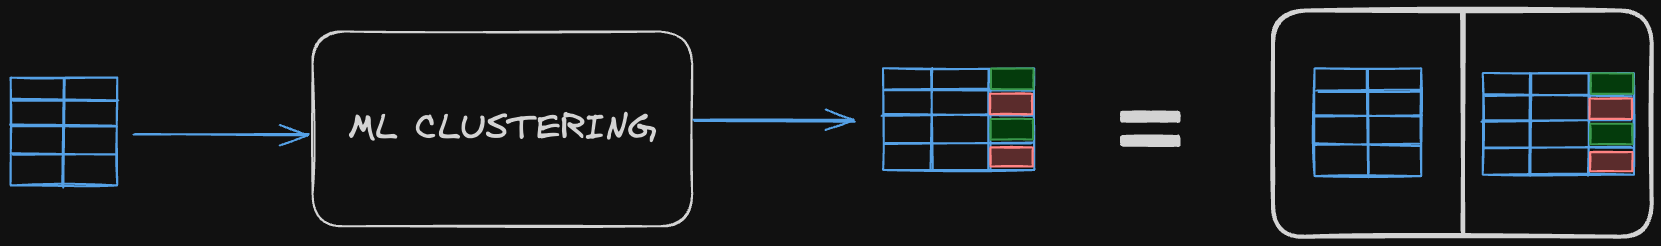

## Instalujemy wymagane biblioteki (conda wymagana)

- otwórz terminal
- uruchom `conda activate od_zera_do_ai`
- uruchom `conda install -y 'pycaret[full]'`

In [ ]:
from pycaret.clustering import load_model, predict_model
import pandas as pd

## Jak używać modelu `klastrowania`?

In [ ]:
# clustering_pipeline został wytrenowany na danych
# z dwoma kolumami `x` i `y` zawierającymi liczby całkowite
model = load_model("clustering_pipeline")

In [ ]:
df = pd.DataFrame([
    {"x": 200, "y": 350},
    {"x": 100, "y": 100},
    {"x": 300, "y": 300},
])
predict_model(model, data=df)

## Zamykamy model w funkcji

In [ ]:
def assign_data_to_cluster(df, predicted_column_name="grupa", cluster_mapping=None):
    model = load_model("clustering_pipeline")
    df = predict_model(model, data=df)
    if cluster_mapping:
        df["Cluster"] = df["Cluster"].map(cluster_mapping)

    df = df.rename(columns={"Cluster": predicted_column_name})
    return df

In [ ]:
assign_data_to_cluster(
    df=pd.DataFrame([
        {"x": 2, "y": 8},
        {"x": 6, "y": 2},
        {"x": 211, "y": 101},
    ]),
    cluster_mapping={"Cluster 0": "A", "Cluster 1": "B", "Cluster 2": "C"},
)

## Pomysły `gpt-4o` na użycie modelu

### 1. Segmentacja Klientów w Marketingu
Model klastrowania może analizować dane demograficzne, behawioralne i zakupowe klientów, aby odkryć grupy klientów o podobnych cechach. Dzięki temu firmy mogą dostosować kampanie marketingowe do specyficznych segmentów, np. „młode rodziny”, „klienci premium”, „osoby o wysokiej wartości życiowej”.

### 2. Odkrywanie Grup Genów w Badaniach Genetycznych
W genomice modele klastrowania mogą być używane do identyfikacji grup genów o podobnym wzorze ekspresji w różnych próbkach. To może pomóc naukowcom zrozumieć, które geny działają razem i jak wpływają na różne procesy biologiczne.

### 3. Analiza Zachowań Użytkowników w Aplikacjach Mobilnych
Model klastrowania może analizować dane dotyczące sposobu, w jaki użytkownicy korzystają z aplikacji mobilnych (np. czas spędzony w aplikacji, częstość użycia funkcji), aby odkryć grupy użytkowników o podobnych wzorcach zachowań. To może pomóc w personalizacji doświadczeń użytkowników.

### 4. Klastrowanie Produktów w eCommerce
Modele klastrowania mogą być używane do grupowania produktów na podstawie cech, takich jak cena, kategoria, popularność sprzedaży. Dzięki temu można tworzyć rekomendacje zakupowe, zestawy produktów lub kategorie dla klientów.

### 5. Odkrywanie Grup w Danych Demograficznych Miast
Modele klastrowania mogą analizować dane demograficzne mieszkańców miast, takie jak wiek, dochody, wykształcenie, aby odkryć grupy z podobnymi cechami społeczno-ekonomicznymi. Może to pomóc władzom w planowaniu usług publicznych.

### 6. Segmentacja Rynku w Branży Nieruchomości
Model klastrowania może analizować cechy nieruchomości, takie jak lokalizacja, cena, metraż, liczba pokoi, aby odkryć grupy nieruchomości o podobnych cechach. To może pomóc agentom nieruchomości w lepszym targetowaniu ofert do odpowiednich klientów.

### 7. Odkrywanie Wzorców Przestępczości
Policja i organy ścigania mogą używać modeli klastrowania do analizowania danych dotyczących przestępstw, takich jak miejsce, czas i typ przestępstwa, aby odkryć grupy zdarzeń o podobnych cechach. To może pomóc w prewencji i alokacji zasobów.

### 8. Klastrowanie Części w Przemyśle Produkcyjnym
W produkcji modele klastrowania mogą być używane do grupowania części lub komponentów na podstawie cech, takich jak materiał, rozmiar, funkcjonalność. To może pomóc w optymalizacji procesów produkcyjnych i zarządzaniu zapasami.

### 9. Odkrywanie Grup Pacjentów w Analizie Medycznej
W badaniach medycznych modele klastrowania mogą być używane do grupowania pacjentów na podstawie cech klinicznych, takich jak objawy, wyniki badań, historia chorób. To może pomóc w personalizacji leczenia i lepszym zrozumieniu różnych podtypów chorób.

### 10. Segmentacja Firm dla Analiz Rynkowych
Model klastrowania może analizować cechy firm, takie jak wielkość, branża, przychody, aby odkryć grupy firm o podobnych profilach. To może być przydatne dla doradców biznesowych, inwestorów lub dla firm planujących ekspansję na nowe rynki.